# Import Module

In [ ]:
import pandas as pd
import numpy as np

# Mempersiapkan Data

In [ ]:
# Daca data csv
df = pd.read_csv('E:/KP RAFI RIDHO RAMADHAN/data_juni_ST2_7D_clean.csv')
df.head()

,timestamp,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas
0,2024-06-10 13:06:01.353,100.829346,23.213638,74.532692,27.232393,364,4.60,0.00
1,2024-06-10 13:06:01.436,100.875145,27.721346,74.512856,27.275118,363,4.86,0.00
2,2024-06-10 13:06:01.600,100.876099,27.732904,74.476234,27.275118,363,4.60,0.28
3,2024-06-10 13:06:01.763,100.874657,27.744940,74.431984,27.259096,363,4.86,0.00
4,2024-06-10 13:06:01.926,100.874779,27.753908,74.491493,27.301826,363,4.86,0.00


In [ ]:
# Mengubah "Timestamp" menjadi indeks
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index("timestamp")
df = df.sort_index()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 7 columns):
 #   Column          Dtype  
---  ------          -----  
 0   bmp388Pressure  float64
 1   bmp388Temp      float64
 2   sht85Humi       float64
 3   sht85Temp       float64
 4   co2             int64  
 5   bawah           float64
 6   atas            float64
dtypes: float64(6), int64(1)
memory usage: 118.7 MB


# Parameter Tekanan Udara

In [ ]:
R = 8.314472 # Konstanta gas universal (J/mol/K)
df['Temperature (K)'] = df["sht85Temp"] + 273.15 # Suhu (Kelvin)
df['Pressure (Pa)'] = df["bmp388Pressure"] * 1000 # Tekanan udara (Pa)
df['Molar Density of Air (mol/m^3)'] = df['Pressure (Pa)']/(R* df['Temperature (K)']) # Densitas udara (mol/m³)

df.head()

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3)
timestamp,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,74.532692,27.232393,364,4.60,0.00,300.382393,100829.3457,40.371771
2024-06-10 13:06:01.436,100.875145,27.721346,74.512856,27.275118,363,4.86,0.00,300.425118,100875.1450,40.384365
2024-06-10 13:06:01.600,100.876099,27.732904,74.476234,27.275118,363,4.60,0.28,300.425118,100876.0986,40.384747
2024-06-10 13:06:01.763,100.874657,27.744940,74.431984,27.259096,363,4.86,0.00,300.409096,100874.6567,40.386323
2024-06-10 13:06:01.926,100.874779,27.753908,74.491493,27.301826,363,4.86,0.00,300.451826,100874.7787,40.380628


# Parameter Angin

In [ ]:
# Membuat parameter 'w'
df['w'] = df['atas'] - df['bawah']


df.head(30)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w
timestamp,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,74.532692,27.232393,364,4.60,0.00,300.382393,100829.3457,40.371771,-4.60
2024-06-10 13:06:01.436,100.875145,27.721346,74.512856,27.275118,363,4.86,0.00,300.425118,100875.1450,40.384365,-4.86
2024-06-10 13:06:01.600,100.876099,27.732904,74.476234,27.275118,363,4.60,0.28,300.425118,100876.0986,40.384747,-4.32
2024-06-10 13:06:01.763,100.874657,27.744940,74.431984,27.259096,363,4.86,0.00,300.409096,100874.6567,40.386323,-4.86
2024-06-10 13:06:01.926,100.874779,27.753908,74.491493,27.301826,363,4.86,0.00,300.451826,100874.7787,40.380628,-4.86
2024-06-10 13:06:02.091,100.874000,27.758665,74.485390,27.232393,363,4.60,0.00,300.382393,100874.0005,40.389651,-4.60
2024-06-10 13:06:02.254,100.876038,27.762419,74.436562,27.275118,363,4.86,0.00,300.425118,100876.0376,40.384722,-4.86
2024-06-10 13:06:02.422,100.874970,27.761484,74.384674,27.259096,363,4.86,0.00,300.409096,100874.9695,40.386448,-4.86
2024-06-10 13:06:02.583,100.874741,27.759705,74.485390,27.275118,363,4.60,0.00,300.425118,100874.7406,40.384203,-4.60


# Menghitung Fluks

In [ ]:
# Menentukan window waktu rolling mean selama 30 menit
rolling_window = '30min'

In [ ]:
# Menghitung rata-rata bergerak dalam tiap window waktu
df['w_mean_30min'] = df['w'].rolling(rolling_window).mean()
df['c_mean_30min'] = df['co2'].rolling(rolling_window).mean()


In [ ]:
# Menghitung fluktuasi dengan reynold decomposistion
df['w_prime'] = df['w'] - df['w_mean_30min']
df['c_prime'] = df['co2'] - df['c_mean_30min']

In [ ]:
# Menghitung perkalian w_prime dan c_prime
df['w_prime * c_prime (μmol/mol * m/s)'] = df['w_prime'] * df['c_prime']


df.head(50)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s)
timestamp,,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,74.532692,27.232393,364,4.60,0.00,300.382393,100829.3457,40.371771,-4.60,-4.600000,364.000000,0.000000,0.000000,0.000000
2024-06-10 13:06:01.436,100.875145,27.721346,74.512856,27.275118,363,4.86,0.00,300.425118,100875.1450,40.384365,-4.86,-4.730000,363.500000,-0.130000,-0.500000,0.065000
2024-06-10 13:06:01.600,100.876099,27.732904,74.476234,27.275118,363,4.60,0.28,300.425118,100876.0986,40.384747,-4.32,-4.593333,363.333333,0.273333,-0.333333,-0.091111
2024-06-10 13:06:01.763,100.874657,27.744940,74.431984,27.259096,363,4.86,0.00,300.409096,100874.6567,40.386323,-4.86,-4.660000,363.250000,-0.200000,-0.250000,0.050000
2024-06-10 13:06:01.926,100.874779,27.753908,74.491493,27.301826,363,4.86,0.00,300.451826,100874.7787,40.380628,-4.86,-4.700000,363.200000,-0.160000,-0.200000,0.032000
2024-06-10 13:06:02.091,100.874000,27.758665,74.485390,27.232393,363,4.60,0.00,300.382393,100874.0005,40.389651,-4.60,-4.683333,363.166667,0.083333,-0.166667,-0.013889
2024-06-10 13:06:02.254,100.876038,27.762419,74.436562,27.275118,363,4.86,0.00,300.425118,100876.0376,40.384722,-4.86,-4.708571,363.142857,-0.151429,-0.142857,0.021633
2024-06-10 13:06:02.422,100.874970,27.761484,74.384674,27.259096,363,4.86,0.00,300.409096,100874.9695,40.386448,-4.86,-4.727500,363.125000,-0.132500,-0.125000,0.016563
2024-06-10 13:06:02.583,100.874741,27.759705,74.485390,27.275118,363,4.60,0.00,300.425118,100874.7406,40.384203,-4.60,-4.713333,363.111111,0.113333,-0.111111,-0.012593


In [ ]:
# Resample per 30 menit dan hitung rata-rata
df_30min = df.resample('30T').mean(numeric_only=True)


In [ ]:
# Hitung flux Fc per 30 menit
df_30min['C02_flux (μmol/m²/s)'] = df_30min['w_prime * c_prime (μmol/mol * m/s)'] * df_30min['Molar Density of Air (mol/m^3)']

df_30min.head(50)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s),C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,81.746555,26.658762,360.036798,5.644296,0.004946,299.808762,100827.530559,40.448370,-5.639350,-5.728921,362.251085,0.089571,-2.214287,-0.755782,-30.570163
2024-06-10 13:30:00,100.775620,27.077859,84.466928,27.118138,354.093327,4.973995,0.000757,300.268138,100775.619928,40.365614,-4.973237,-5.571046,359.415772,0.597809,-5.322445,-3.179577,-128.345582
2024-06-10 14:00:00,100.800875,26.889366,81.821922,28.754484,351.000000,3.915409,0.000000,301.904484,100800.875297,40.156889,-3.915409,-3.915409,351.000000,0.000000,0.000000,0.000000,0.000000
2024-06-10 14:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06-10 15:00:00,100.824257,26.169551,91.417568,26.450613,351.942138,3.164459,0.063962,299.600613,100824.256839,40.475075,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,0.041690,1.687392
2024-06-10 15:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06-10 16:00:00,100.965157,25.516978,88.755306,25.814818,369.850854,0.000000,0.001394,298.964818,100965.157489,40.617835,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.000806,-0.032735
2024-06-10 16:30:00,100.958938,25.461470,89.676946,25.764373,378.429409,0.000000,0.000253,298.914373,100958.937870,40.622187,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.007936,-0.322394
2024-06-10 17:00:00,101.020787,25.125617,91.423566,25.468921,385.224083,0.000000,0.002884,298.618921,101020.786770,40.687289,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.000424,-0.017263


In [ ]:
df_30min.isna().sum()

bmp388Pressure                        2
bmp388Temp                            2
sht85Humi                             2
sht85Temp                             2
co2                                   2
bawah                                 2
atas                                  2
Temperature (K)                       2
Pressure (Pa)                         2
Molar Density of Air (mol/m^3)        2
w                                     2
w_mean_30min                          2
c_mean_30min                          2
w_prime                               2
c_prime                               2
w_prime * c_prime (μmol/mol * m/s)    2
C02_flux (μmol/m²/s)                  2
dtype: int64

In [ ]:
# Isi data NaN dengan Interpolasi Time
data_30min_filled = df_30min.interpolate(method='time')

data_30min_filled.head(20)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s),C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,81.746555,26.658762,360.036798,5.644296,0.004946,299.808762,100827.530559,40.448370,-5.639350,-5.728921,362.251085,0.089571,-2.214287,-0.755782,-30.570163
2024-06-10 13:30:00,100.775620,27.077859,84.466928,27.118138,354.093327,4.973995,0.000757,300.268138,100775.619928,40.365614,-4.973237,-5.571046,359.415772,0.597809,-5.322445,-3.179577,-128.345582
2024-06-10 14:00:00,100.800875,26.889366,81.821922,28.754484,351.000000,3.915409,0.000000,301.904484,100800.875297,40.156889,-3.915409,-3.915409,351.000000,0.000000,0.000000,0.000000,0.000000
2024-06-10 14:30:00,100.812566,26.529459,86.619745,27.602548,351.471069,3.539934,0.031981,300.752548,100812.566068,40.315982,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,0.020845,0.843696
2024-06-10 15:00:00,100.824257,26.169551,91.417568,26.450613,351.942138,3.164459,0.063962,299.600613,100824.256839,40.475075,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,0.041690,1.687392
2024-06-10 15:30:00,100.894707,25.843265,90.086437,26.132715,360.896496,1.582229,0.032678,299.282715,100894.707164,40.546455,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.020442,0.827329
2024-06-10 16:00:00,100.965157,25.516978,88.755306,25.814818,369.850854,0.000000,0.001394,298.964818,100965.157489,40.617835,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.000806,-0.032735
2024-06-10 16:30:00,100.958938,25.461470,89.676946,25.764373,378.429409,0.000000,0.000253,298.914373,100958.937870,40.622187,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.007936,-0.322394
2024-06-10 17:00:00,101.020787,25.125617,91.423566,25.468921,385.224083,0.000000,0.002884,298.618921,101020.786770,40.687289,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.000424,-0.017263


In [ ]:
data_30min_filled.isna().sum()

bmp388Pressure                        0
bmp388Temp                            0
sht85Humi                             0
sht85Temp                             0
co2                                   0
bawah                                 0
atas                                  0
Temperature (K)                       0
Pressure (Pa)                         0
Molar Density of Air (mol/m^3)        0
w                                     0
w_mean_30min                          0
c_mean_30min                          0
w_prime                               0
c_prime                               0
w_prime * c_prime (μmol/mol * m/s)    0
C02_flux (μmol/m²/s)                  0
dtype: int64

In [ ]:
# Isi data NaN dengan Interpolasi Time
final_flux = data_30min_filled

final_flux.head(20)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s),C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,81.746555,26.658762,360.036798,5.644296,0.004946,299.808762,100827.530559,40.448370,-5.639350,-5.728921,362.251085,0.089571,-2.214287,-0.755782,-30.570163
2024-06-10 13:30:00,100.775620,27.077859,84.466928,27.118138,354.093327,4.973995,0.000757,300.268138,100775.619928,40.365614,-4.973237,-5.571046,359.415772,0.597809,-5.322445,-3.179577,-128.345582
2024-06-10 14:00:00,100.800875,26.889366,81.821922,28.754484,351.000000,3.915409,0.000000,301.904484,100800.875297,40.156889,-3.915409,-3.915409,351.000000,0.000000,0.000000,0.000000,0.000000
2024-06-10 14:30:00,100.812566,26.529459,86.619745,27.602548,351.471069,3.539934,0.031981,300.752548,100812.566068,40.315982,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,0.020845,0.843696
2024-06-10 15:00:00,100.824257,26.169551,91.417568,26.450613,351.942138,3.164459,0.063962,299.600613,100824.256839,40.475075,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,0.041690,1.687392
2024-06-10 15:30:00,100.894707,25.843265,90.086437,26.132715,360.896496,1.582229,0.032678,299.282715,100894.707164,40.546455,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.020442,0.827329
2024-06-10 16:00:00,100.965157,25.516978,88.755306,25.814818,369.850854,0.000000,0.001394,298.964818,100965.157489,40.617835,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.000806,-0.032735
2024-06-10 16:30:00,100.958938,25.461470,89.676946,25.764373,378.429409,0.000000,0.000253,298.914373,100958.937870,40.622187,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.007936,-0.322394
2024-06-10 17:00:00,101.020787,25.125617,91.423566,25.468921,385.224083,0.000000,0.002884,298.618921,101020.786770,40.687289,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.000424,-0.017263


In [ ]:
# Konversi satuan agar menjadi ton/Ha/s
final_flux['ton_hectare_flux'] = final_flux['C02_flux (μmol/m²/s)'] * 44.001 * 1e-8


final_flux.head(20)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s),C02_flux (μmol/m²/s),ton_hectare_flux
timestamp,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,81.746555,26.658762,360.036798,5.644296,0.004946,299.808762,100827.530559,40.448370,-5.639350,-5.728921,362.251085,0.089571,-2.214287,-0.755782,-30.570163,-1.345118e-05
2024-06-10 13:30:00,100.775620,27.077859,84.466928,27.118138,354.093327,4.973995,0.000757,300.268138,100775.619928,40.365614,-4.973237,-5.571046,359.415772,0.597809,-5.322445,-3.179577,-128.345582,-5.647334e-05
2024-06-10 14:00:00,100.800875,26.889366,81.821922,28.754484,351.000000,3.915409,0.000000,301.904484,100800.875297,40.156889,-3.915409,-3.915409,351.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
2024-06-10 14:30:00,100.812566,26.529459,86.619745,27.602548,351.471069,3.539934,0.031981,300.752548,100812.566068,40.315982,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,0.020845,0.843696,3.712347e-07
2024-06-10 15:00:00,100.824257,26.169551,91.417568,26.450613,351.942138,3.164459,0.063962,299.600613,100824.256839,40.475075,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,0.041690,1.687392,7.424694e-07
2024-06-10 15:30:00,100.894707,25.843265,90.086437,26.132715,360.896496,1.582229,0.032678,299.282715,100894.707164,40.546455,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.020442,0.827329,3.640329e-07
2024-06-10 16:00:00,100.965157,25.516978,88.755306,25.814818,369.850854,0.000000,0.001394,298.964818,100965.157489,40.617835,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.000806,-0.032735,-1.440354e-08
2024-06-10 16:30:00,100.958938,25.461470,89.676946,25.764373,378.429409,0.000000,0.000253,298.914373,100958.937870,40.622187,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.007936,-0.322394,-1.418566e-07
2024-06-10 17:00:00,101.020787,25.125617,91.423566,25.468921,385.224083,0.000000,0.002884,298.618921,101020.786770,40.687289,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.000424,-0.017263,-7.595991e-09


In [ ]:
# Konversi satuan agar menjadi ton/Ha/year
sec_to_year = 31557600
ton_flux_year = final_flux['ton_hectare_flux'] * sec_to_year
final_flux['ton_flux_year'] = ton_flux_year


final_flux.head(20)

,bmp388Pressure,bmp388Temp,sht85Humi,sht85Temp,co2,bawah,atas,Temperature (K),Pressure (Pa),Molar Density of Air (mol/m^3),w,w_mean_30min,c_mean_30min,w_prime,c_prime,w_prime * c_prime (μmol/mol * m/s),C02_flux (μmol/m²/s),ton_hectare_flux,ton_flux_year
timestamp,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,81.746555,26.658762,360.036798,5.644296,0.004946,299.808762,100827.530559,40.448370,-5.639350,-5.728921,362.251085,0.089571,-2.214287,-0.755782,-30.570163,-1.345118e-05,-424.486877
2024-06-10 13:30:00,100.775620,27.077859,84.466928,27.118138,354.093327,4.973995,0.000757,300.268138,100775.619928,40.365614,-4.973237,-5.571046,359.415772,0.597809,-5.322445,-3.179577,-128.345582,-5.647334e-05,-1782.163065
2024-06-10 14:00:00,100.800875,26.889366,81.821922,28.754484,351.000000,3.915409,0.000000,301.904484,100800.875297,40.156889,-3.915409,-3.915409,351.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
2024-06-10 14:30:00,100.812566,26.529459,86.619745,27.602548,351.471069,3.539934,0.031981,300.752548,100812.566068,40.315982,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,0.020845,0.843696,3.712347e-07,11.715275
2024-06-10 15:00:00,100.824257,26.169551,91.417568,26.450613,351.942138,3.164459,0.063962,299.600613,100824.256839,40.475075,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,0.041690,1.687392,7.424694e-07,23.430551
2024-06-10 15:30:00,100.894707,25.843265,90.086437,26.132715,360.896496,1.582229,0.032678,299.282715,100894.707164,40.546455,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.020442,0.827329,3.640329e-07,11.488005
2024-06-10 16:00:00,100.965157,25.516978,88.755306,25.814818,369.850854,0.000000,0.001394,298.964818,100965.157489,40.617835,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.000806,-0.032735,-1.440354e-08,-0.454541
2024-06-10 16:30:00,100.958938,25.461470,89.676946,25.764373,378.429409,0.000000,0.000253,298.914373,100958.937870,40.622187,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.007936,-0.322394,-1.418566e-07,-4.476653
2024-06-10 17:00:00,101.020787,25.125617,91.423566,25.468921,385.224083,0.000000,0.002884,298.618921,101020.786770,40.687289,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.000424,-0.017263,-7.595991e-09,-0.239711


# Visualisasi Data

In [ ]:
import matplotlib.pyplot as plt

**Visualisasi data ECS Rafi**

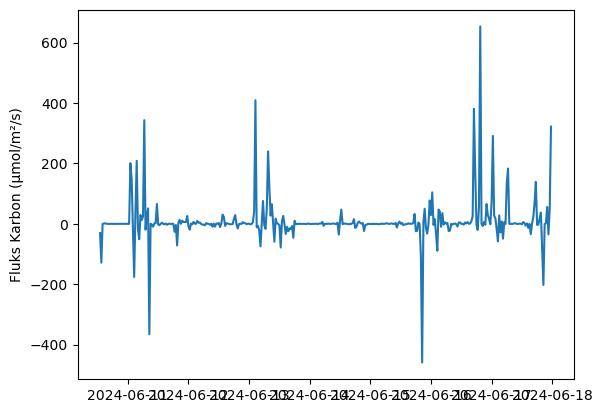

In [ ]:
# Menampilkan visualisasi
plt.plot(final_flux['C02_flux (μmol/m²/s)'])
plt.ylabel('Fluks Karbon (μmol/m²/s)')
plt.show()

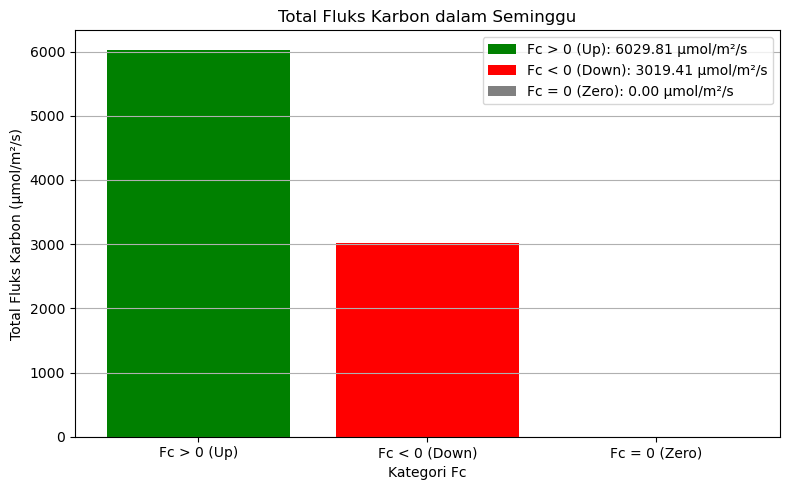

In [ ]:
# Ambil kolom Fc
Fc = final_flux['C02_flux (μmol/m²/s)']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].sum()
Fc_neg_sum = -Fc[Fc < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Visualisasi data Licor**

In [ ]:
licor = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN/Data/data.csv")

licor.head()

,fluks_licor
0,120.188
1,172.375
2,677.048
3,16.939
4,164.982


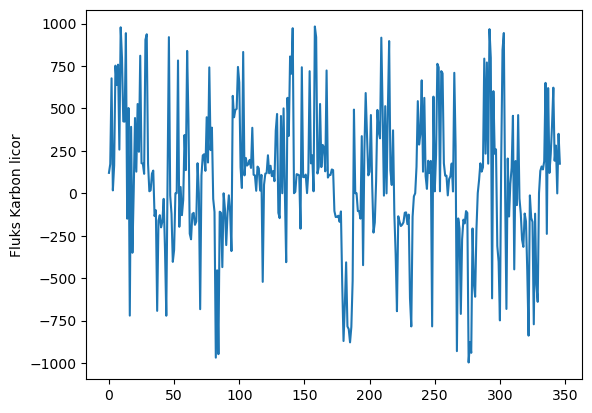

In [ ]:
# Menampilkan visualisasi
plt.plot(licor['fluks_licor'])
plt.ylabel('Fluks Karbon licor')
plt.show()

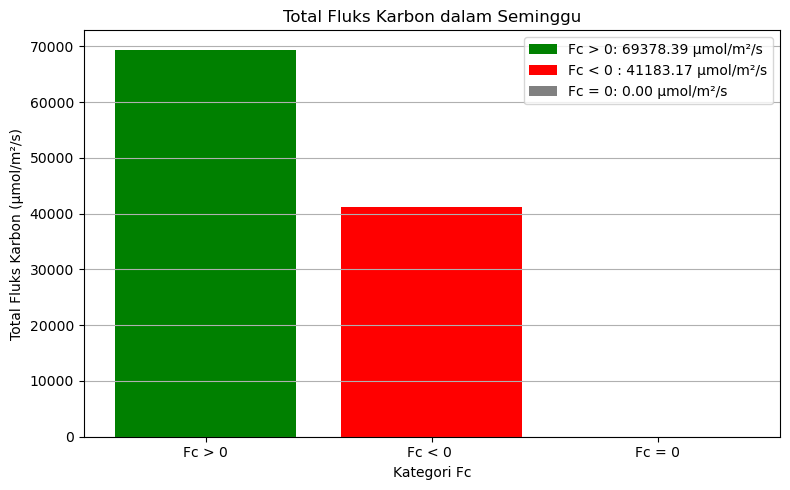

In [ ]:
# Ambil kolom Fc
licor = licor['fluks_licor']


# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = licor[licor > 0].sum()
Fc_neg_sum = -licor[licor < 0].sum()
Fc_zero_sum = licor[licor == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Visualisasi Perhitungan Fluks Kak Irgi**

In [ ]:
kak_irgi = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN/Fec_perdetik.csv")

kak_irgi.head(20)

,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec
0,2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,0.934325,3.117843,0.033156,472.677872,473.764525,-1.086653,91.821885,0.006358
1,2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,0.934389,3.117888,0.031418,471.823902,472.342324,-0.518422,96.120637,0.002544
2,2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,0.934241,3.118216,0.031535,471.880556,472.133926,-0.253371,95.764946,-0.000982
3,2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,0.934539,3.122667,0.031505,471.866002,472.058647,-0.192645,95.995429,-0.000030
4,2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,0.934160,3.117706,0.031491,472.596863,472.088477,0.508386,95.885491,-0.024127
5,2024-06-10 00:06:06,99.142072,93.411410,25.909245,458.000000,0.111252,0.000000,-0.111252,-0.065835,-0.045418,3.337258,0.934114,3.117379,0.031444,472.868822,472.237377,0.631445,96.024693,-0.013174
6,2024-06-10 00:06:07,99.055558,93.436078,25.913697,458.000000,0.033434,0.000000,-0.033434,-0.062606,0.029171,3.338137,0.934361,3.119025,0.031488,472.890362,472.337360,0.553002,95.936533,0.006826
7,2024-06-10 00:06:08,99.053024,93.433790,25.927940,458.000000,0.035076,0.000000,-0.035076,-0.058215,0.023139,3.340954,0.934338,3.121580,0.031514,472.903242,472.410965,0.492277,95.931444,0.004925
8,2024-06-10 00:06:09,99.076754,93.412427,25.932391,458.000000,0.230730,0.000000,-0.230730,-0.073772,-0.156958,3.341835,0.934124,3.121689,0.031508,472.900135,472.468057,0.432079,95.955066,-0.028317
9,2024-06-10 00:06:10,99.259235,93.421328,25.918147,458.000000,0.139412,0.000000,-0.139412,-0.079761,-0.059651,3.339017,0.934213,3.119353,0.031426,472.860331,472.510399,0.349932,96.139881,-0.008171


In [ ]:
# Mengubah "Timestamp" menjadi indeks
kak_irgi['timestamp'] = pd.to_datetime(kak_irgi['timestamp'])
kak_irgi = kak_irgi.set_index("timestamp")
kak_irgi = kak_irgi.sort_index()

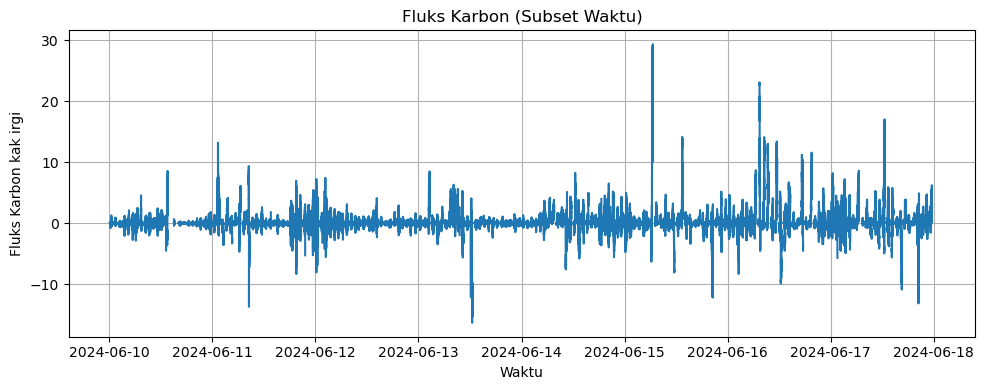

In [ ]:
# Tentukan rentang waktu
start_time = '2024-06-10 00:06:01'
end_time   = '2024-06-18 00:06:01'

# Filter data sesuai rentang
filtered = kak_irgi.loc[start_time:end_time]

# Tampilkan plot
plt.figure(figsize=(10, 4))
plt.plot(filtered['Fec'])
plt.ylabel('Fluks Karbon kak irgi')
plt.xlabel('Waktu')
plt.title('Fluks Karbon (Subset Waktu)')
plt.grid(True)
plt.tight_layout()
plt.show()

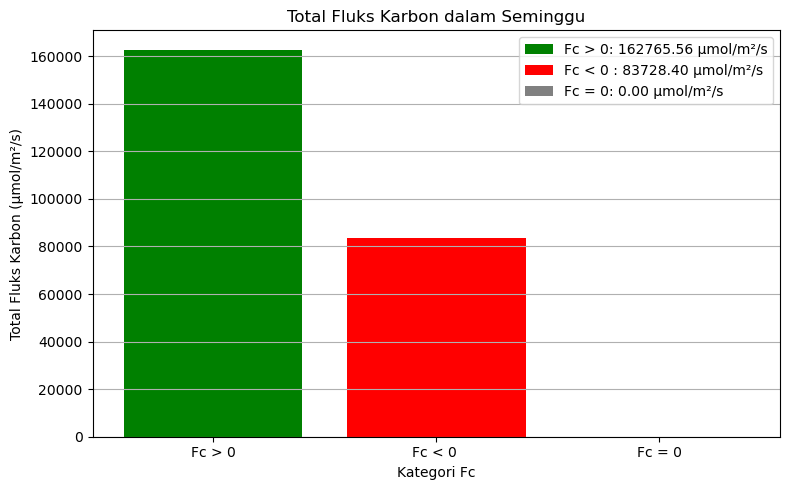

In [ ]:
kakirgi = filtered['Fec']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = kakirgi[kakirgi > 0].sum()
Fc_neg_sum = -kakirgi[kakirgi < 0].sum()
Fc_zero_sum = kakirgi[kakirgi == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Menyimpan Data

In [ ]:
# Simpan data ke csv
final_flux.to_csv('E:/KP RAFI RIDHO RAMADHAN/Hasil/final_data_2.csv')